# g01 - Graph Analytics: Contiguous Farmland, Agro-ecological Communities and Crop Competition

Suitability maps say *where* a crop fits, cell by cell. Farming happens on contiguous land, and neighbouring cells share
climate, soil and water, so the 1 km grid is naturally a **graph**: every cell is a node, every pair of cells that share an
edge (rook neighbours) is connected. Graph algorithms then answer questions a cell-by-cell table cannot:

1. **Contiguous suitable land.** For each crop, the connected components of the cells with an index of 5,000 or more are
   the farmable patches: how many, how large, how fragmented, and which cells hold a patch together (articulation points).
2. **Contiguous recommendation blocks.** The same for the recommended crop (the dashboard's rule).
3. **Agro-ecological communities.** Louvain community detection on the grid graph, with edges weighted by how similar the
   physical conditions of the two cells are, groups land into regions that are internally alike.
4. **Crop competition network.** A second, small graph: the ten crops are nodes, and an edge says how much suitable land two
   crops share (Jaccard overlap), i.e. where they compete for the same land.
5. **Scalable graph processing.** The same graph on Apache Spark with GraphFrames (degrees, connected components of every
   crop's suitable land, label propagation), checked against NetworkX.

Data: GAEZ v5 at 1 km and the 14 physical drivers of all 9,333 cells. Results go to `scripts/modeling/results/g01_*`, the
per-cell graph attributes to `datasets/processed/experiments/g01_nodes.parquet` (read by the dashboard's 'Graph Analytics'
page).

In [1]:
import sys
import time
from itertools import combinations
from pathlib import Path

# Make exp_lib importable no matter where the notebook is launched from.
HERE = next(p for p in (Path.cwd(), Path.cwd() / "scripts" / "modeling") if (p / "exp_lib.py").exists())
sys.path.insert(0, str(HERE))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import normalized_mutual_info_score

import exp_lib as E
import exp_spark as S
from threadpoolctl import threadpool_limits

sys.path.insert(0, str(E.PROJECT_ROOT / "scripts" / "dashboard"))
import streamlit.logger  # noqa: E402
streamlit.logger.set_log_level("error")   # the dashboard module is used here without a Streamlit server
import common as C  # noqa: E402  (crop names, land-cover names, the recommendation rule of the dashboard)

threadpool_limits(E.N_JOBS)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 160)
SUITABLE = E.NOT_RECOMMENDED_THRESHOLD

In [2]:
df = E.load_table(complete=False)                     # all 9,333 cells
df["label"] = C.recommend(df, C.CROPS, "Relative", res="1 km")["label"].to_numpy()
df["land_cover"] = df["landcover_majority"].round().map(C.WORLDCOVER_CLASSES).fillna("Unknown")
drivers = df[E.feature_columns()]
Z = ((drivers.fillna(drivers.median()) - drivers.mean()) / drivers.std()).to_numpy()

# Nodes = cells; edges = rook neighbours on the 1 km grid, weighted by the similarity of their physical conditions.
where = {(r, c): i for i, (r, c) in enumerate(zip(df["row"], df["col"]))}
pairs = [(i, where[(r + dr, c + dc)]) for (r, c), i in where.items() for dr, dc in ((1, 0), (0, 1)) if (r + dr, c + dc) in where]
d2 = np.array([((Z[i] - Z[j]) ** 2).sum() for i, j in pairs])
sim = np.exp(-d2 / np.median(d2))
ids = df["grid_id"].to_numpy()
t0 = time.perf_counter()
G = nx.Graph()
G.add_nodes_from(ids)
G.add_weighted_edges_from(((ids[i], ids[j], float(w)) for (i, j), w in zip(pairs, sim)), weight="similarity")
build_s = time.perf_counter() - t0
islands = sorted((len(cc) for cc in nx.connected_components(G)), reverse=True)
summary = {"nodes (1 km cells)": G.number_of_nodes(), "edges (shared cell sides)": G.number_of_edges(),
           "mean degree": 2 * G.number_of_edges() / G.number_of_nodes(), "connected components (land masses)": len(islands),
           "cells on the largest land mass": islands[0], "cells on the other land masses": sum(islands[1:])}
pd.Series(summary, name="value").round(2).to_frame()

,value
nodes (1 km cells),9333.00
edges (shared cell sides),18156.00
mean degree,3.89
connected components (land masses),10.00
cells on the largest land mass,9171.00
cells on the other land masses,162.00


## 1. Contiguous suitable land per crop

In [3]:
rows, node_cols = [], {}
for c in C.CROPS:
    cells = ids[(df[f"gaez1k_index_{c}"] >= SUITABLE).to_numpy()]
    H = G.subgraph(cells)
    comps = sorted(nx.connected_components(H), key=len, reverse=True)
    sizes = np.array([len(x) for x in comps]) if comps else np.zeros(0, dtype=int)
    size_of = {n: len(x) for x in comps for n in x}
    patch_of = {n: k for k, x in enumerate(comps) for n in x}
    node_cols[f"patch_size__{c}"] = df["grid_id"].map(size_of)
    node_cols[f"patch_id__{c}"] = df["grid_id"].map(patch_of)
    bottlenecks = len(list(nx.articulation_points(H.subgraph(comps[0])))) if comps and sizes[0] > 2 else 0
    on_edge = sum(H.degree(n) < G.degree(n) for n in cells)   # suitable cells that touch unsuitable land
    rows.append({"crop": C.CROP_LABELS[c], "suitable km2": int(sizes.sum()), "patches": len(comps),
                 "largest patch km2": int(sizes.max()) if len(sizes) else 0,
                 "share in largest patch": sizes.max() / sizes.sum() if len(sizes) else np.nan,
                 "share in patches >= 25 km2": sizes[sizes >= 25].sum() / sizes.sum() if len(sizes) else np.nan,
                 "single-cell patches": int((sizes == 1).sum()), "share of cells on a patch edge": on_edge / max(len(cells), 1),
                 "bottleneck cells in largest patch": bottlenecks})
patches = pd.DataFrame(rows).set_index("crop")
E.save_table(patches.round(4), "g01_patches", index=True)
patches.round(3)

,suitable km2,patches,largest patch km2,share in largest patch,share in patches >= 25 km2,single-cell patches,share of cells on a patch edge,bottleneck cells in largest patch
crop,,,,,,,,
Rice,2181,48,1828,0.838,0.939,16,0.231,38
Maize,8,4,3,0.375,0.000,1,0.875,1
Cassava,3060,68,2015,0.658,0.917,22,0.279,25
Soybean,256,25,112,0.438,0.680,9,0.629,14
Oil palm,3938,64,3443,0.874,0.931,17,0.262,73
Rubber,0,0,0,NaN,NaN,0,0.000,0
Sugarcane,1186,35,1005,0.847,0.894,17,0.309,35
Coffee,3110,67,2126,0.684,0.899,17,0.286,28
Cacao,2508,65,1834,0.731,0.917,24,0.315,51


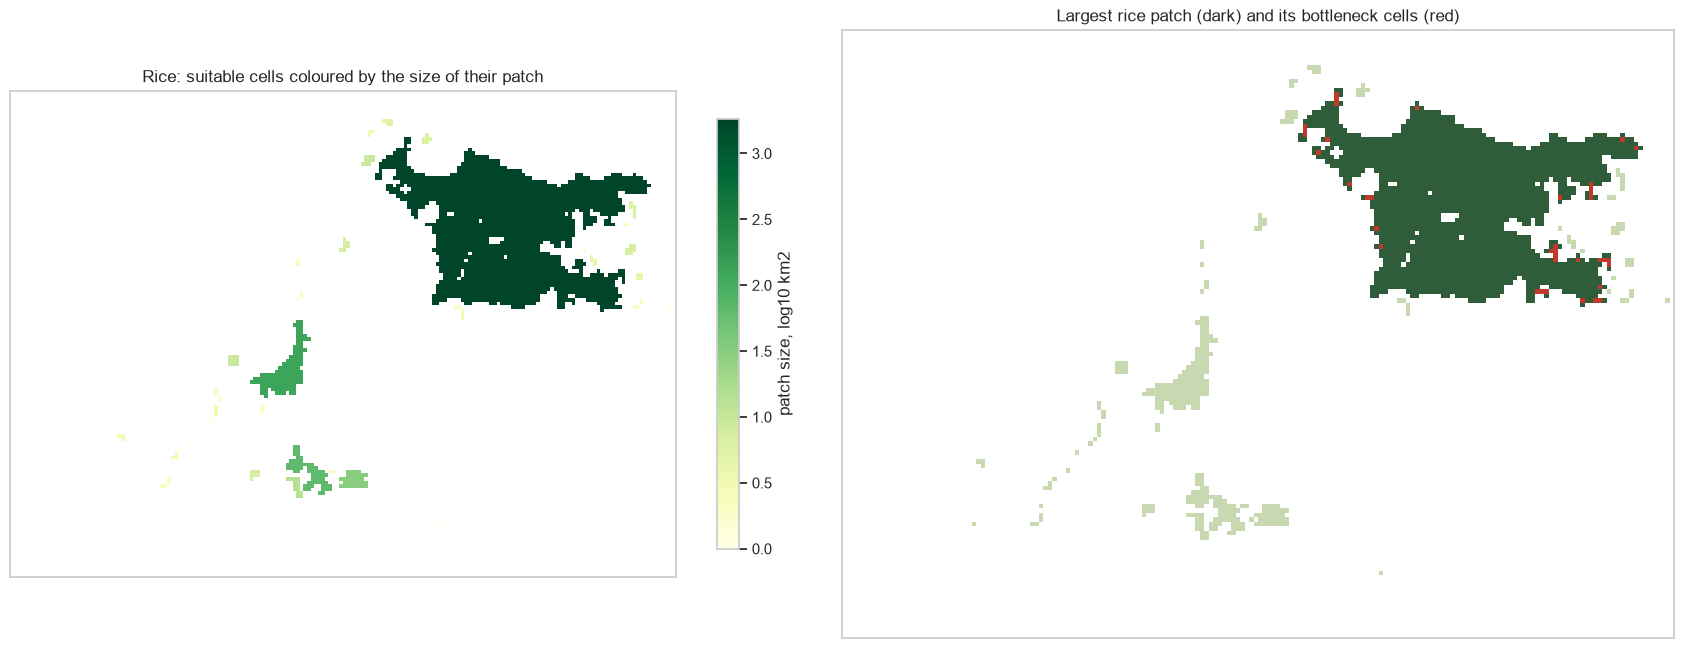

In [4]:
crop = "rice"
shape = (df["row"].max() + 1, df["col"].max() + 1)


def on_grid(values):
    z = np.full(shape, np.nan)
    z[df["row"].to_numpy(), df["col"].to_numpy()] = np.asarray(values, dtype=float)
    return z


fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
im = axes[0].imshow(on_grid(np.log10(node_cols[f"patch_size__{crop}"])), origin="lower", cmap="YlGn", interpolation="nearest")
axes[0].set(title=f"{C.CROP_LABELS[crop]}: suitable cells coloured by the size of their patch")
fig.colorbar(im, ax=axes[0], shrink=0.7, label="patch size, log10 km2")
largest = node_cols[f"patch_id__{crop}"] == 0
H0 = G.subgraph(ids[largest.to_numpy()])
art = set(nx.articulation_points(H0))
z = np.where(largest, 1.0, np.where(node_cols[f"patch_id__{crop}"].notna(), 0.5, np.nan))
z = np.where(df["grid_id"].isin(art), 2.0, z)
axes[1].imshow(on_grid(z), origin="lower", cmap=plt.matplotlib.colors.ListedColormap(["#C8D8B0", "#2F5D3A", "#C0392B"]),
               vmin=0.25, vmax=2.25, interpolation="nearest")
axes[1].set(title=f"Largest {C.CROP_LABELS[crop].lower()} patch (dark) and its bottleneck cells (red)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
E.save_fig(fig, "g01_patches_rice")
plt.show()

## 2. Contiguous blocks of the recommended crop

In [5]:
rows = []
for label, grp in df.groupby("label"):
    if label in ("Not recommended", "No cropland / water"):
        continue
    sizes = np.array(sorted((len(x) for x in nx.connected_components(G.subgraph(grp["grid_id"]))), reverse=True))
    rows.append({"recommended crop": label, "cells": int(sizes.sum()), "blocks": len(sizes), "largest block km2": int(sizes[0]),
                 "mean block km2": sizes.mean(), "share in blocks >= 25 km2": sizes[sizes >= 25].sum() / sizes.sum()})
blocks = pd.DataFrame(rows).set_index("recommended crop").sort_values("cells", ascending=False)
E.save_table(blocks.round(4), "g01_label_blocks", index=True)
blocks.round(3)

,cells,blocks,largest block km2,mean block km2,share in blocks >= 25 km2
recommended crop,,,,,
Coffee,954,104,383,9.173,0.711
Coconut,855,49,256,17.449,0.828
Oil palm,581,108,99,5.380,0.492
Cacao,540,99,91,5.455,0.530
Cassava,486,76,121,6.395,0.646
Rice,369,49,176,7.531,0.680
Soybean,134,11,112,12.182,0.836
Sugarcane,131,41,30,3.195,0.229


## 3. Agro-ecological communities (Louvain on the similarity-weighted grid graph)

Louvain maximises modularity: it groups cells that are densely and strongly connected to each other, here neighbours with
similar climate, soil and terrain. Communities therefore follow both space and conditions.

In [6]:
t0 = time.perf_counter()
communities = sorted(nx.community.louvain_communities(G, weight="similarity", resolution=1.0, seed=0), key=len, reverse=True)
louvain_s = time.perf_counter() - t0
modularity = nx.community.modularity(G, communities, weight="similarity")
community_of = {n: k + 1 for k, cs in enumerate(communities) for n in cs}
df["community"] = df["grid_id"].map(community_of)
summary.update({"Louvain communities": len(communities), "modularity": modularity,
                "NMI community vs recommended crop": normalized_mutual_info_score(df["community"], df["label"]),
                "NMI community vs land cover": normalized_mutual_info_score(df["community"], df["land_cover"])})
profile = df.groupby("community").agg(cells=("grid_id", "size"), elevation_m=("elevation_mean_m", "mean"),
                                      rainfall_mm=("bio12_precip_annual_mm", "mean"), temperature_c=("bio1_temp_mean_c", "mean"),
                                      cropland_pct=("cropland_pct", "mean"))
top = df.groupby("community")["label"].agg(lambda s: s.value_counts().index[0])
share = df.groupby("community")["label"].agg(lambda s: s.value_counts(normalize=True).iloc[0])
profile["most frequent recommendation"], profile["its share"] = top, share
profile["main land cover"] = df.groupby("community")["land_cover"].agg(lambda s: s.value_counts().index[0])
E.save_table(profile.round(3), "g01_communities", index=True)
print(f"{len(communities)} communities, modularity {modularity:.3f}, Louvain {louvain_s:.1f} s")
profile.head(15).round(2)

77 communities, modularity 0.946, Louvain 0.8 s


,cells,elevation_m,rainfall_mm,temperature_c,cropland_pct,most frequent recommendation,its share,main land cover
community,,,,,,,,
1,284,191.83,3451.01,24.61,4.22,Not recommended,0.78,Tree cover
2,253,490.12,4145.25,22.48,2.10,Not recommended,1.00,Tree cover
3,239,72.82,3166.24,25.67,17.83,Not recommended,0.54,Tree cover
4,237,244.05,3685.66,24.42,6.62,Not recommended,0.94,Tree cover
5,235,85.33,3293.86,25.45,6.83,Not recommended,0.71,Tree cover
6,231,143.97,3121.11,25.00,14.61,Not recommended,0.41,Tree cover
7,231,97.54,2405.41,25.69,17.01,Coffee,0.43,Tree cover
8,228,117.52,2121.32,25.74,5.06,Not recommended,0.75,Tree cover
9,219,314.27,2652.90,24.18,7.81,Not recommended,0.79,Tree cover


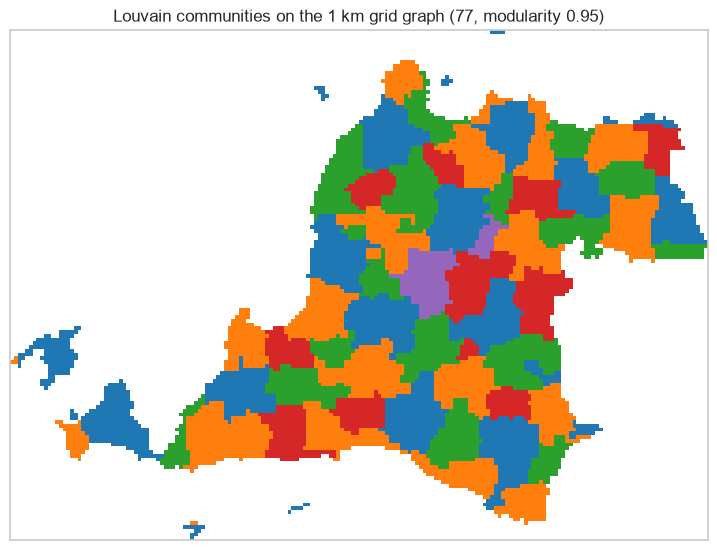

In [7]:
# Colour the communities so that no two neighbouring communities share a colour (greedy graph colouring of the
# community adjacency graph).
A = nx.Graph()
A.add_nodes_from(range(1, len(communities) + 1))
A.add_edges_from((community_of[u], community_of[v]) for u, v in G.edges if community_of[u] != community_of[v])
colour = nx.greedy_color(A, strategy="largest_first")
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(on_grid(df["community"].map(colour)), origin="lower", cmap="tab10", vmin=-0.5, vmax=9.5, interpolation="nearest")
ax.set(title=f"Louvain communities on the 1 km grid graph ({len(communities)}, modularity {modularity:.2f})")
ax.set_xticks([])
ax.set_yticks([])
E.save_fig(fig, "g01_communities")
plt.show()

## 4. Crop competition: shared and nested suitable land

A second, small graph with the crops as nodes answers *on which land do the crops compete?* in two ways:

- **Overlap (undirected).** Two crops are linked by the Jaccard index of their suitable land (shared area / combined
  area, links from 0.05); Louvain on this graph groups crops that compete for the same fields.
- **Nesting (directed).** An arrow A -> B means that at least 95 % of A's suitable land is also suitable for B. The
  transitive reduction of this graph (its Hasse diagram) keeps only the direct nestings and orders the crops from niche to
  widely suitable.

In [8]:
NESTED = 0.95
suitable_sets = {c: set(ids[(df[f"gaez1k_index_{c}"] >= SUITABLE).to_numpy()]) for c in C.CROPS}
CG = nx.Graph()
CG.add_nodes_from(C.CROPS)
rows = []
for a, b in combinations(C.CROPS, 2):
    A_, B_ = suitable_sets[a], suitable_sets[b]
    inter, union = len(A_ & B_), len(A_ | B_)
    jac = inter / union if union else 0.0
    rows.append({"crop A": C.CROP_LABELS[a], "crop B": C.CROP_LABELS[b], "shared km2": inter, "jaccard": jac,
                 "share of A's land suitable for B": inter / len(A_) if A_ else np.nan,
                 "share of B's land suitable for A": inter / len(B_) if B_ else np.nan})
    if jac >= 0.05:
        CG.add_edge(a, b, jaccard=jac, shared=inter)
crop_edges = pd.DataFrame(rows).sort_values("jaccard", ascending=False)
E.save_table(crop_edges.round(4), "g01_crop_graph")

# Nesting: A -> B when (almost) all of A's suitable land is suitable for B as well.
D = nx.DiGraph()
D.add_nodes_from(c for c in C.CROPS if suitable_sets[c])
D.add_edges_from((a, b) for a in D for b in D
                 if a != b and len(suitable_sets[a] & suitable_sets[b]) >= NESTED * len(suitable_sets[a]))
Dc = nx.condensation(D)            # crops with (almost) identical suitable land would merge into one node
H = nx.transitive_reduction(Dc)    # Hasse diagram: only the direct nestings
member = {n: sorted(Dc.nodes[n]["members"], key=C.CROPS.index) for n in Dc}
name = {n: " = ".join(C.CROP_LABELS[c] for c in member[n]) for n in Dc}
area = {n: len(set().union(*(suitable_sets[c] for c in member[n]))) for n in Dc}
nesting = pd.DataFrame([{"inner crop": name[u], "lies within": name[v],
                         "share of inner land": min(len(suitable_sets[a] & suitable_sets[b]) / len(suitable_sets[a])
                                                    for a in member[u] for b in member[v])} for u, v in H.edges])
E.save_table(nesting.round(4), "g01_crop_nesting")

groups = nx.community.louvain_communities(CG, weight="jaccard", seed=0)
strength = dict(CG.degree(weight="jaccard"))
crop_nodes = pd.DataFrame({"crop": [C.CROP_LABELS[c] for c in C.CROPS],
                           "suitable km2": [len(suitable_sets[c]) for c in C.CROPS],
                           "competition strength (sum of jaccard)": [strength.get(c, 0.0) for c in C.CROPS],
                           "overlap group (Louvain)": [next(k + 1 for k, g in enumerate(groups) if c in g) for c in C.CROPS],
                           "crops nested inside it": [D.in_degree(c) if c in D else 0 for c in C.CROPS],
                           "crops it is nested in": [D.out_degree(c) if c in D else 0 for c in C.CROPS]})
E.save_table(crop_nodes.round(4), "g01_crop_nodes")
summary.update({"crop overlap groups (Louvain)": len(groups), "nesting links (95 %)": D.number_of_edges(),
                "direct nestings (Hasse edges)": H.number_of_edges()})
display(crop_edges.head(10).round(3))
display(nesting.round(3))
crop_nodes.sort_values("suitable km2", ascending=False).round(3)

,crop A,crop B,shared km2,jaccard,share of A's land suitable for B,share of B's land suitable for A
43,Coffee,Coconut,2734,0.837,0.879,0.946
23,Cassava,Coconut,2636,0.795,0.861,0.912
21,Cassava,Coffee,2718,0.787,0.888,0.874
32,Oil palm,Coffee,3079,0.776,0.782,0.990
18,Cassava,Oil palm,3057,0.776,0.999,0.776
22,Cassava,Cacao,2396,0.755,0.783,0.955
8,Rice,Coconut,2181,0.755,1.000,0.755
7,Rice,Cacao,1988,0.736,0.912,0.793
1,Rice,Cassava,2171,0.707,0.995,0.709
42,Coffee,Cacao,2326,0.707,0.748,0.927


,inner crop,lies within,share of inner land
0,Cassava,Oil palm,0.999
1,Coffee,Oil palm,0.990
2,Coconut,Oil palm,0.972
3,Rice,Cassava,0.995
4,Rice,Coffee,0.996
5,Rice,Coconut,1.000
6,Cacao,Cassava,0.955
7,Soybean,Rice,1.000
8,Soybean,Cacao,1.000
9,Sugarcane,Rice,0.993


,crop,suitable km2,competition strength (sum of jaccard),overlap group (Louvain),crops nested inside it,crops it is nested in
4,Oil palm,3938,3.799,2,8,0
7,Coffee,3110,4.267,2,4,1
2,Cassava,3060,4.292,2,5,1
9,Coconut,2890,4.278,2,4,1
8,Cacao,2508,4.095,2,3,2
0,Rice,2181,4.102,2,3,4
6,Sugarcane,1186,2.609,2,1,6
3,Soybean,256,0.657,2,1,6
1,Maize,8,0.000,1,0,8
5,Rubber,0,0.000,3,0,0


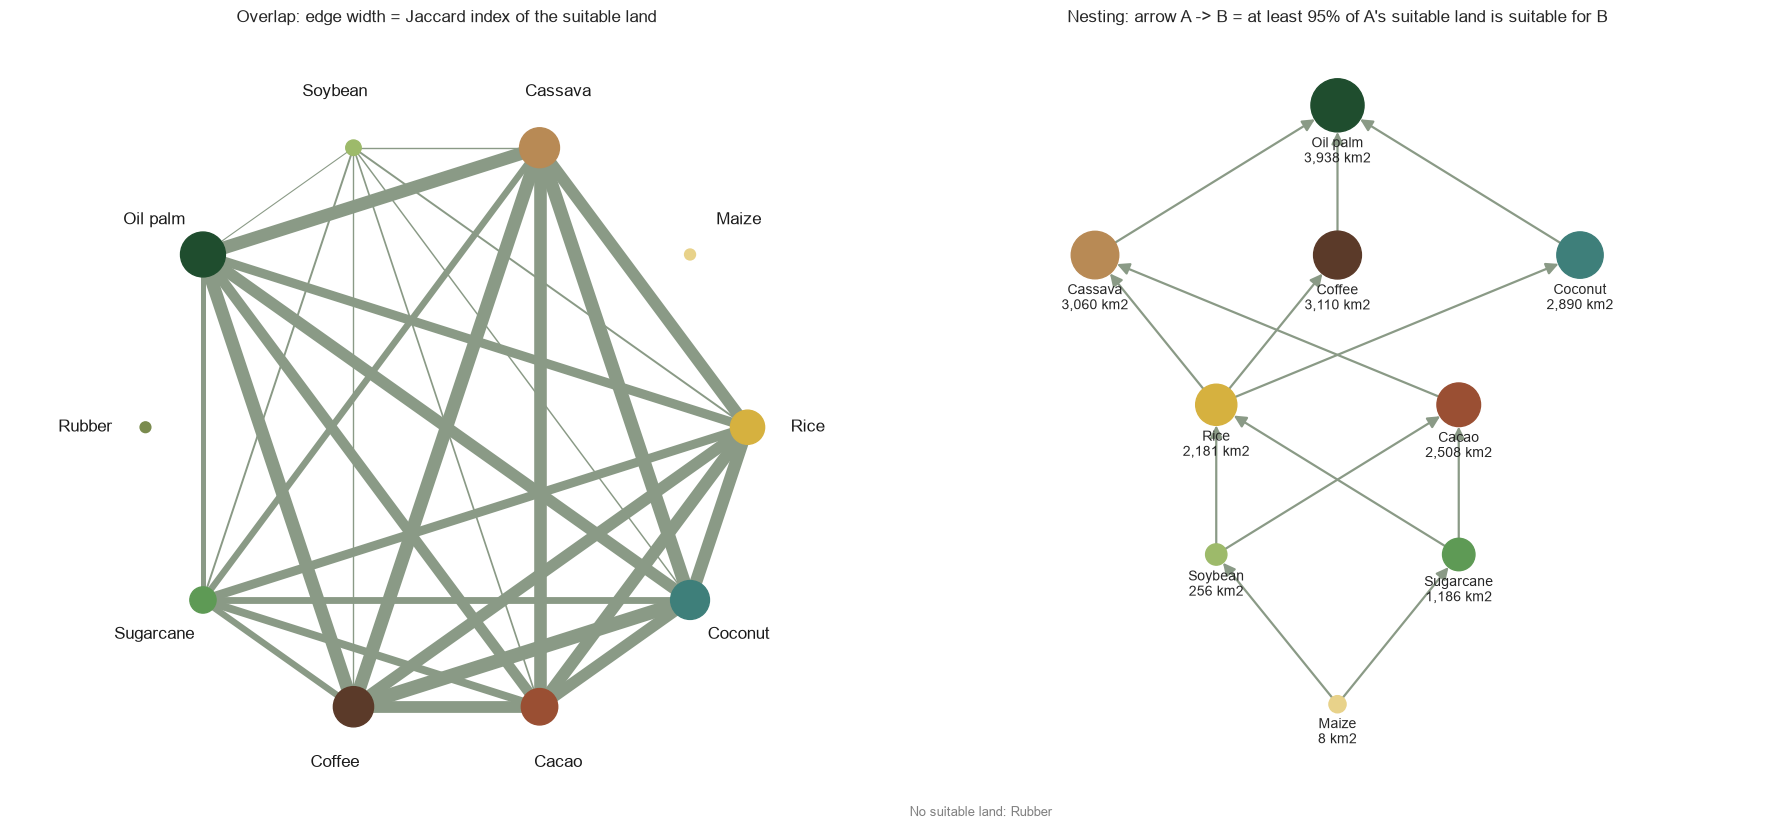

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8.5))
ax = axes[0]
pos = nx.circular_layout(CG)
nx.draw_networkx_edges(CG, pos, width=[12 * CG[a][b]["jaccard"] for a, b in CG.edges], edge_color="#8A9A86", ax=ax)
nx.draw_networkx_nodes(CG, pos, node_size=[60 + len(suitable_sets[c]) / 4 for c in CG.nodes],
                       node_color=[C.LABEL_COLORS[C.CROP_LABELS[c]] for c in CG.nodes], ax=ax)
nx.draw_networkx_labels(CG, {k: (1.2 * x, 1.2 * y) for k, (x, y) in pos.items()}, {c: C.CROP_LABELS[c] for c in CG.nodes}, ax=ax)
ax.set(title="Overlap: edge width = Jaccard index of the suitable land", xlim=(-1.45, 1.45), ylim=(-1.35, 1.35))
ax.axis("off")

ax = axes[1]
gens = list(nx.topological_generations(H))
hpos = {n: (k - (len(g) - 1) / 2, i) for i, g in enumerate(gens)
        for k, n in enumerate(sorted(g, key=lambda n: C.CROPS.index(member[n][0])))}
sizes = [150 + area[n] / 3 for n in H.nodes]
nx.draw_networkx_edges(H, hpos, ax=ax, arrows=True, arrowstyle="-|>", arrowsize=18, width=1.6, edge_color="#8A9A86",
                       node_size=sizes)
nx.draw_networkx_nodes(H, hpos, ax=ax, node_size=sizes, node_color=[C.LABEL_COLORS[C.CROP_LABELS[member[n][0]]] for n in H.nodes])
for n, s_ in zip(H.nodes, sizes):
    ax.annotate(f"{name[n]}\n{area[n]:,} km2", hpos[n], xytext=(0, -(s_ ** 0.5) / 2 - 3), textcoords="offset points",
                ha="center", va="top", fontsize=10)
missing = [C.CROP_LABELS[c] for c in C.CROPS if not suitable_sets[c]]
ax.set(title=f"Nesting: arrow A -> B = at least {NESTED:.0%} of A's suitable land is suitable for B",
       xlim=(min(x for x, _ in hpos.values()) - 0.8, max(x for x, _ in hpos.values()) + 0.8), ylim=(-0.8, len(gens) - 0.5))
if missing:
    ax.text(0.01, 0.01, "No suitable land: " + ", ".join(missing), transform=ax.transAxes, fontsize=9, color="grey")
ax.axis("off")
plt.tight_layout()
E.save_fig(fig, "g01_crop_graph")
plt.show()

## 5. The same graph at scale: GraphFrames on Apache Spark

GraphFrames represents a graph as two Spark DataFrames (vertices, edges) and runs its algorithms as distributed Spark jobs,
so the same analysis scales from this province to a whole country. Here it runs in local mode with 6 cores and must agree
with NetworkX: degrees, the land masses, and the suitable-land patches of all ten crops. Label propagation is its fast,
scalable community algorithm (a different method from Louvain, so it is compared, not expected to match), run for 5, 10
and 20 rounds. This section
takes about five minutes: every connected-components run is a series of small Spark jobs.

In [10]:
t0 = time.perf_counter()
spark = S.session("g01-graphframes", packages=[S.GRAPHFRAMES])
S.enable_graphframes(spark)
from graphframes import GraphFrame  # noqa: E402
from pyspark.sql import functions as F  # noqa: E402

# Integer vertex ids (the row of df) spare GraphFrames the re-indexing of string ids; grid_id stays an attribute.
vert_pdf = pd.DataFrame({"id": np.arange(len(df), dtype="int64"), "grid_id": ids,
                         **{f"s_{c}": (df[f"gaez1k_index_{c}"] >= SUITABLE).to_numpy() for c in C.CROPS}})
edge_pdf = pd.DataFrame({"src": np.array([i for i, _ in pairs], dtype="int64"),
                         "dst": np.array([j for _, j in pairs], dtype="int64"), "similarity": sim})
V, EE = spark.createDataFrame(vert_pdf).cache(), spark.createDataFrame(edge_pdf).cache()
gf = GraphFrame(V, EE)
print(f"GraphFrame: {V.count():,} vertices, {EE.count():,} edges")
timings = [{"step": "start, build the graph", "NetworkX (s)": build_s, "GraphFrames (s)": time.perf_counter() - t0}]
checks = []


def clock(fn):
    t0 = time.perf_counter()
    out = fn()
    return out, time.perf_counter() - t0


def suitable_subgraph(c):
    # One crop's suitable land as a GraphFrame with fresh inputs. Filtering the cached graph instead (gf.filterVertices)
    # nests its cached plans in every round of connected components until their text no longer fits in memory; a local
    # checkpoint cuts that lineage.
    v = V.filter(F.col(f"s_{c}")).select("id").localCheckpoint()
    e = (EE.join(v.withColumnRenamed("id", "src"), "src").join(v.withColumnRenamed("id", "dst"), "dst")
         .select("src", "dst").localCheckpoint())
    return GraphFrame(v, e)


def nx_patches():
    sizes = {c: [len(x) for x in nx.connected_components(G.subgraph(ids[vert_pdf[f"s_{c}"].to_numpy()]))] for c in C.CROPS}
    return {c: (len(v), max(v, default=0)) for c, v in sizes.items()}


def gf_patches():
    out = {}
    for c in C.CROPS:
        sizes = suitable_subgraph(c).connectedComponents().toPandas()["component"].value_counts()
        out[c] = (len(sizes), int(sizes.max()) if len(sizes) else 0)
    return out


deg_gf, t_gf = clock(lambda: gf.degrees.toPandas().set_index("id")["degree"])
deg_nx, t_nx = clock(lambda: pd.Series(dict(G.degree())))
deg_gf = pd.Series(deg_gf.reindex(np.arange(len(df))).fillna(0).to_numpy(), index=ids)   # row id -> grid_id
deg_nx = deg_nx.reindex(ids)
timings.append({"step": "node degrees", "NetworkX (s)": t_nx, "GraphFrames (s)": t_gf})
checks.append({"check": "node degrees (sum)", "NetworkX": int(deg_nx.sum()), "GraphFrames": int(deg_gf.sum()),
               "equal": bool((deg_gf == deg_nx).all())})

cc_gf, t_gf = clock(lambda: gf.connectedComponents().select("component").distinct().count())
cc_nx, t_nx = clock(lambda: nx.number_connected_components(G))
timings.append({"step": "connected components, whole grid", "NetworkX (s)": t_nx, "GraphFrames (s)": t_gf})
checks.append({"check": "land masses", "NetworkX": cc_nx, "GraphFrames": cc_gf, "equal": cc_gf == cc_nx})

p_gf, t_gf = clock(gf_patches)
p_nx, t_nx = clock(nx_patches)
timings.append({"step": "connected components, suitable land of 10 crops", "NetworkX (s)": t_nx, "GraphFrames (s)": t_gf})
checks += [{"check": f"{C.CROP_LABELS[c]}: patches / largest km2", "NetworkX": "%d / %d" % p_nx[c],
            "GraphFrames": "%d / %d" % p_gf[c], "equal": p_nx[c] == p_gf[c]} for c in C.CROPS]

# Label propagation runs a fixed number of rounds; three lengths show how far its result has settled.
lpa_rows = []
for rounds in (5, 10, 20):
    lab, secs = clock(lambda: gf.labelPropagation(maxIter=rounds).select("id", "label").toPandas().set_index("id")["label"])
    lab = lab.reindex(np.arange(len(df))).to_numpy()
    lpa_rows.append({"rounds": rounds, "communities": len(np.unique(lab)), "seconds": secs,
                     "NMI vs Louvain": normalized_mutual_info_score(df["community"], lab)})
lpa_table = pd.DataFrame(lpa_rows)
E.save_table(lpa_table.round(4), "g01_label_propagation")
last = lpa_rows[-1]
timings.append({"step": "communities (Louvain / label propagation, 20 rounds)", "NetworkX (s)": louvain_s,
                "GraphFrames (s)": last["seconds"]})
lpa_nmi = last["NMI vs Louvain"]
checks.append({"check": "communities (Louvain / label propagation, 20 rounds; different methods)",
               "NetworkX": len(communities), "GraphFrames": last["communities"], "equal": None})
display(lpa_table.round(3))
S.stop(spark)   # also removes the checkpoints GraphFrames leaves behind

check, timing = pd.DataFrame(checks), pd.DataFrame(timings)
E.save_table(check, "g01_graphframes_check")
E.save_table(timing.round(3), "g01_graphframes_timings")
verdicts = check["equal"].dropna().astype(bool)
summary.update({"GraphFrames checks passed": f"{int(verdicts.sum())} / {len(verdicts)}",
                "NMI label propagation vs Louvain": lpa_nmi})
display(timing.round(2))
check

GraphFrame: 9,333 vertices, 18,156 edges


,rounds,communities,seconds,NMI vs Louvain
0,5,1900,1.784,0.665
1,10,1705,1.377,0.668
2,20,1687,2.469,0.668


,step,NetworkX (s),GraphFrames (s)
0,"start, build the graph",0.03,8.58
1,node degrees,0.01,1.97
2,"connected components, whole grid",0.01,39.09
3,"connected components, suitable land of 10 crops",0.05,196.06
4,"communities (Louvain / label propagation, 20 r...",0.77,2.47


,check,NetworkX,GraphFrames,equal
0,node degrees (sum),36312,36312,True
1,land masses,10,10,True
2,Rice: patches / largest km2,48 / 1828,48 / 1828,True
3,Maize: patches / largest km2,4 / 3,4 / 3,True
4,Cassava: patches / largest km2,68 / 2015,68 / 2015,True
5,Soybean: patches / largest km2,25 / 112,25 / 112,True
6,Oil palm: patches / largest km2,64 / 3443,64 / 3443,True
7,Rubber: patches / largest km2,0 / 0,0 / 0,True
8,Sugarcane: patches / largest km2,35 / 1005,35 / 1005,True
9,Coffee: patches / largest km2,67 / 2126,67 / 2126,True


## Summary and per-cell output

In [11]:
nodes = pd.DataFrame({"grid_id": ids, "community": df["community"].to_numpy(), "label": df["label"].to_numpy(),
                      **{k: v.to_numpy() for k, v in node_cols.items()}})
print(E.save_oof(nodes, "g01_nodes"), nodes.shape)
graph_summary = pd.Series(summary, name="value").to_frame()
E.save_table(graph_summary.rename_axis("measure").reset_index(), "g01_graph_summary")
graph_summary

D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\experiments\g01_nodes.parquet (9333, 23)


,value
nodes (1 km cells),9333
edges (shared cell sides),18156
mean degree,3.89071
connected components (land masses),10
cells on the largest land mass,9171
cells on the other land masses,162
Louvain communities,77
modularity,0.945751
NMI community vs recommended crop,0.265616
NMI community vs land cover,0.182958


## Findings

- **The graph.** 9,333 nodes (1 km cells) and 18,156 edges (shared sides), mean degree 3.9. It has 10 connected
  components: the mainland (9,171 cells) and 9 islands (162 cells).
- **Suitable land is mostly contiguous.** For the seven crops with large suitable areas (rice, cassava, oil palm,
  sugarcane, coffee, cacao, coconut), 66-87 % of the land with an index of 5,000 or more forms one contiguous patch and
  89-94 % lies in patches of at least 25 km². Soybean is the exception: 256 km² in 25 patches, 44 % in the largest and
  63 % of its cells on a patch edge. Maize has 8 km² and rubber none at 1 km (its highest index in Banten is 3,333).
- **A few cells hold the large patches together.** The articulation points of the largest patch mark narrow corridors:
  73 cells for oil palm (3,443 km²), 38 for rice (1,828 km²), 51 for cacao. Losing one of them, to a road, a settlement
  or another land use, splits the patch.
- **Recommendation blocks differ in compactness.** Under the dashboard's rule (relative ranking, all ten crops), coconut
  and soybean are recommended in large blocks (83-84 % of their cells in blocks of 25 km² or more; coconut's blocks
  average 17 km²). Sugarcane is the most scattered (41 blocks of 3.2 km² on average, 23 % in large blocks), and oil palm
  and cacao are fragmented as well (about 100 blocks each, 5.4-5.5 km² on average, about half in large blocks).
- **Agro-ecological communities.** Louvain on the similarity-weighted graph finds 77 communities (median 129 km²) with a
  modularity of 0.95. The value is high partly because grid graphs separate compact regions easily: every cell has at
  most four neighbours. Community means range from 1,627 to 4,349 mm of rain and from 17.3 to 27.1 °C. The communities
  agree more with the recommendation map (NMI 0.27) than with today's land cover (0.18), so they follow the growing
  conditions behind the crop map. In 49 of the 77, 'Not recommended' is the most frequent label: much of the province,
  largely under tree cover, has no crop at 5,000 or more.
- **Crops compete for one core of good land.** The seven large-area crops overlap strongly (Jaccard 0.30-0.84), and
  Louvain puts all eight crops linked at a Jaccard index of 0.05 or more into one group (maize and rubber stay alone).
  The nesting graph shows why. The suitable lands are nested: 29 of the 72 ordered pairs of the nine crops with suitable
  land meet the 95 % rule, and the Hasse diagram has five levels (maize -> soybean, sugarcane -> rice, cacao -> cassava,
  coffee, coconut -> oil palm). Oil palm's suitable land contains that of all eight other crops. Every km² suitable for
  rice is also suitable for coconut, and 99.5 % or more of it for cassava, coffee and oil palm. Jaccard hides this: oil
  palm and sugarcane have a Jaccard index of only 0.30, yet all of sugarcane's suitable land is suitable for oil palm.
  The crops therefore do not divide the province into separate niches. The real choice is which crop gets the shared
  core, and that is what the recommendation rule decides.
- **The same graph on Spark.** GraphFrames reproduces every count of NetworkX (12 of 12 checks: degrees, land masses,
  patches of all ten crops). On 9,333 nodes it is far slower: 39 s against 0.006 s for the components of the whole grid,
  196 s against 0.05 s for the ten crops, because each connected-components run is a chain of small Spark jobs. Label
  propagation is GraphFrames' scalable community method. It ignores the weights and settles at 1,687 small communities
  after 20 rounds (1,900 after 5), with an NMI of 0.67 against Louvain. One engineering lesson: an iterative algorithm
  on a filtered, cached graph nested its query plans until their text exhausted the 4 GB driver heap. Building every
  subgraph from fresh, locally checkpointed inputs fixed it, and the same fix applies on a cluster, whose driver holds
  the plans as well.